# 錯誤更正碼 1109

1102 的 BCH codes 用代數換來很強的保證：  
更正 $t$ 個 errors 只需要約 $mt$ 個 parity bits。  
但它的 decoder 只處理 hard decisions，  
而且 parity checks 都很重。  
（很重的意思是 parity checks 會一次 check 很多 bits）  
（而會這樣的根本原因是它們的 dual code 也很好）

今天換一個方向：用很多很小的 parity checks，  
每個 bit 只出現在少數幾個 checks 中，  
decoder 只在相鄰的 bits 與 checks 之間傳遞訊息。  
這就是 LDPC（low-density parity-check）codes 的想法。  
今天從最簡單的例子 product codes 開始，  
一般的 LDPC codes 留到下週。

食譜
- Product code：每個 row 與每個 column 都是 codeword。
- Peeling：輪流用 rows 與 columns 補 erasures，卡在 stopping sets。
- Tanner graph：VNs 與 CNs 組成的二部圖。
- 高維 product code：每個方向解一次，density evolution 是精確的。
- BSC 上改用 Hamming codes，誤更正造成 threshold。
- Elias：各方向越來越長，rate 是正的，但離 capacity 很遠。

## Product Codes

### 把 bits 排成矩形

令 $\mathcal C_1$ 與 $\mathcal C_2$ 是 binary linear codes，  
參數分別是 $[n_1, k_1, d_1]$ 與 $[n_2, k_2, d_2]$。  
它們的 **product code** $\mathcal C_1 \otimes \mathcal C_2$  
由下列的 $n_1 \times n_2$ binary 矩陣 $X$ 組成：  
$X$ 的每個 column 都屬於 $\mathcal C_1$，每個 row 都屬於 $\mathcal C_2$。  
把 $X$ 一個 row 接一個 row 攤平，就得到長度 $n_1 n_2$ 的 linear code。  
Elias 在 1954 年提出這個構造。

最簡單的例子是兩個 $[3, 2, 2]$ single parity-check codes：  
$3 \times 3$ 矩陣的每個 row 與每個 column 都有偶數個 $1$。

左上角的 $2 \times 2$ 放訊息，  
右邊的 column 放 row parities $p_i = u_{i1} + u_{i2}$，  
下面的 row 放 column parities $q_j = u_{1j} + u_{2j}$：
$$X = \begin{pmatrix}
u_{11} & u_{12} & p_1 \\
u_{21} & u_{22} & p_2 \\
q_1 & q_2 & r
\end{pmatrix}.$$

右下角的 $r$ 有兩種算法：  
第三個 row 的 parity $q_1 + q_2$，  
或第三個 column 的 parity $p_1 + p_2$。  
兩者都等於 $u_{11} + u_{12} + u_{21} + u_{22}$，所以不會矛盾。  
這個 check on checks 不是巧合，  
下一個定理對一般的 $\mathcal C_1, \mathcal C_2$ 證明同樣的事。

### Dimension 與 minimum distance

**定理：** $\mathcal C_1 \otimes \mathcal C_2$ 是
$[n_1 n_2, k_1 k_2, d_1 d_2]$ code。

證明 dimension：令 $G_1, G_2$ 是 generator matrices，  
對 $k_1 \times k_2$ 矩陣 $U$，令
$$X = G_1^\top U G_2.$$
$X$ 的每個 row 是 $G_2$ 的 rows 的線性組合，所以屬於 $\mathcal C_2$。

同樣地，$X$ 的每個 column 是 $G_1^\top$ 的 columns 的線性組合，  
也就是 $G_1$ 的 rows 的線性組合，所以屬於 $\mathcal C_1$。  
$G_1, G_2$ 的 rows 都線性獨立，所以 $U \mapsto G_1^\top U G_2$ 是一對一的。

反過來，任取 product code 中的 $X$。  
$X$ 的 rows 屬於 $\mathcal C_2$，所以 $X = A G_2$，其中 $A$ 是 $n_1 \times k_2$ 矩陣。  
$G_2$ 的 rank 是 $k_2$，  
所以有 $n_2 \times k_2$ 矩陣 $R$ 使 $G_2 R = I$，於是 $A = XR$。  
$XR$ 的每個 column 是 $X$ 的 columns 的線性組合，屬於 $\mathcal C_1$，  
所以 $A = G_1^\top U$。  
因此 $X = G_1^\top U G_2$，dimension 是 $k_1 k_2$。

證明 minimum distance：非零的 $X$ 有一個非零的 row，  
它屬於 $\mathcal C_2$，至少有 $d_2$ 個 $1$。  
這些 $1$ 所在的 $d_2$ 個 columns 都是 $\mathcal C_1$ 的非零 codewords，  
各至少有 $d_1$ 個 $1$。  
所以 $\operatorname{wt}(X) \ge d_1 d_2$。  
反過來，取 weight 為 $d_1$ 的 $a \in \mathcal C_1$
與 weight 為 $d_2$ 的 $b \in \mathcal C_2$，  
$X = a^\top b$ 的 weight 恰好是 $d_1 d_2$。

兩個 $[3, 2, 2]$ 的 product code 是 $[9, 4, 4]$。  
Minimum-weight codewords 是矩形的四個角，例如
$$\begin{pmatrix}
1 & 1 & 0 \\
1 & 1 & 0 \\
0 & 0 & 0
\end{pmatrix}.$$

從 $3$ 個 rows 選 $2$ 個，再從 $3$ 個 columns 選 $2$ 個，  
共有 $9$ 個這樣的 codewords。

下面用 SageMath 建出 $[9, 4, 4]$。  
由 $X_{ab} = \sum_{i,j}(G_1)_{ia} U_{ij} (G_2)_{jb}$，  
把 $U$ 與 $X$ 都依 rows 攤平時，  
generator matrix 是 Kronecker product $G_1 \otimes G_2$，  
也就是 SageMath 的 `tensor_product`；  
這也是 product code 記號的由來。

In [1]:
G1 = matrix(GF(2), [[1, 0, 1], [0, 1, 1]])
G = G1.tensor_product(G1)
print(G)

[1 0 1|0 0 0|1 0 1]
[0 1 1|0 0 0|0 1 1]
[-----+-----+-----]
[0 0 0|1 0 1|1 0 1]
[0 0 0|0 1 1|0 1 1]


In [2]:
from collections import Counter
from itertools import combinations, product

C = [vector(GF(2), u) * G for u in product(GF(2), repeat=4)]
print(sorted(Counter(c.hamming_weight() for c in C).items()))

[(0, 1), (4, 9), (6, 6)]


Weight 為 $6$ 的 $6$ 個 codewords  
是 $3 \times 3$ permutation matrices 的補集：  
每個 row 與每個 column 都恰好有兩個 $1$。  
和 0907 講義的 extended Hamming $[8, 4, 4]$ code 相比，  
$[9, 4, 4]$ 多用了一個 bit。  
Product code 的優點不在參數，而在 decoding。

### 在 BEC 上輪流解 rows 與 columns

$\operatorname{BEC}(\epsilon)$：  
每個 bit 以機率 $\epsilon$ 變成 erasure symbol $\mathrm e$，沒被擦除的一定正確。  
在 single parity-check code 中，若一個 row 恰好有一個 $\mathrm e$，  
它就等於同一個 row 其他 bits 的和；  
若有兩個以上的 $\mathrm e$，這個 row 本身無法決定它們。

**Peeling decoder** 重複下列步驟：  
找一個恰好有一個 $\mathrm e$ 的 row 或 column，用 parity 補回它。  
直到沒有這樣的 row 與 column 為止。

例如傳送 $u_{11} = u_{12} = u_{21} = 1$、$u_{22} = 0$ 的 codeword，  
第一個 row 的三個 bits 與 $u_{21}$ 被擦除：
$$\begin{pmatrix}
1 & 1 & 0 \\
1 & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}
\quad\longrightarrow\quad
\begin{pmatrix}
\mathrm e & \mathrm e & \mathrm e \\
\mathrm e & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}.$$

第一個 row 有三個 $\mathrm e$，暫時不能用。  
第二個 row 只有一個 $\mathrm e$，補成 $0 + 1 = 1$。  
接著三個 columns 都只剩一個 $\mathrm e$，依序補成 $1$、$1$、$0$。

回填的過程如下，粗體是那一步補回的 bit：
$$\begin{aligned}
&\begin{pmatrix}
\mathrm e & \mathrm e & \mathrm e \\
\mathrm e & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}
\xrightarrow{\text{row }2}
\begin{pmatrix}
\mathrm e & \mathrm e & \mathrm e \\
\mathbf 1 & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}
\xrightarrow{\text{column }1}
\begin{pmatrix}
\mathbf 1 & \mathrm e & \mathrm e \\
1 & 0 & 1 \\
0 & 1 & 1
\end{pmatrix} \\
&\quad\xrightarrow{\text{column }2}
\begin{pmatrix}
1 & \mathbf 1 & \mathrm e \\
1 & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}
\xrightarrow{\text{column }3}
\begin{pmatrix}
1 & 1 & \mathbf 0 \\
1 & 0 & 1 \\
0 & 1 & 1
\end{pmatrix}.
\end{aligned}$$

四個 erasures 全部補回，  
但 minimum distance $4$ 只保證三個 erasures。  
這是 product code 的常態：minimum distance 只描述最壞的情形，  
大部分超過 $d - 1$ 個 erasures 的 patterns 仍然解得開。

但也有解不開的 patterns。  
若被擦除的是矩形的四個角，  
每個 row 與每個 column 都恰好有兩個 $\mathrm e$，peeling 一步也動不了。

而且兩種填法都滿足所有 parity checks：
$$\begin{pmatrix}
\mathrm e & \mathrm e & 0 \\
\mathrm e & \mathrm e & 1 \\
0 & 1 & 1
\end{pmatrix}
\longrightarrow
\begin{pmatrix}
\mathbf 1 & \mathbf 1 & 0 \\
\mathbf 1 & \mathbf 0 & 1 \\
0 & 1 & 1
\end{pmatrix}
\quad\text{or}\quad
\begin{pmatrix}
\mathbf 0 & \mathbf 0 & 0 \\
\mathbf 0 & \mathbf 1 & 1 \\
0 & 1 & 1
\end{pmatrix}.$$

兩種填法相差的正是這個矩形，它是 weight 為 $4$ 的 codeword，  
所以任何 decoder 都無法分辨。

$6$ 個 $\mathrm e$ 也可能卡住，而且不必包含任何矩形。  
例如只留下對角線，兩種填法同樣都滿足所有 parity checks：
$$\begin{pmatrix}
1 & \mathrm e & \mathrm e \\
\mathrm e & 0 & \mathrm e \\
\mathrm e & \mathrm e & 1
\end{pmatrix}
\longrightarrow
\begin{pmatrix}
1 & \mathbf 1 & \mathbf 0 \\
\mathbf 1 & 0 & \mathbf 1 \\
\mathbf 0 & \mathbf 1 & 1
\end{pmatrix}
\quad\text{or}\quad
\begin{pmatrix}
1 & \mathbf 0 & \mathbf 1 \\
\mathbf 0 & 0 & \mathbf 0 \\
\mathbf 1 & \mathbf 0 & 1
\end{pmatrix}.$$

每個 row 與每個 column 都恰好有兩個 $\mathrm e$，peeling 動不了。  
兩種填法相差 $3 \times 3$ permutation matrix 的補集，  
也就是 weight 為 $6$ 的 codeword。

下面數出每種 erasures 個數 $w$ 下，  
peeling 成功的 patterns 有幾個。

`cells` 列出 $9$ 個位置，  
`checks` 列出 $3$ 個 rows 與 $3$ 個 columns 各自包含的位置。  
`peel` 每次找一個恰好包含一個 $\mathrm e$ 的 check，把那個 $\mathrm e$ 補回，  
最後回傳補不回來的位置。

In [3]:
cells = [(a, b) for a in range(3) for b in range(3)]
checks = [[(a, b) for b in range(3)] for a in range(3)] + [[(a, b) for a in range(3)] for b in range(3)]

In [4]:
def peel(erased, checks):
    erased = set(erased)
    while True:
        singles = [ch for ch in checks if len(erased.intersection(ch)) == 1]
        if not singles:
            return erased
        erased -= set(singles[0])

作為對照，若有非零 codeword 的 support  
包含於 erasures 的集合 $E$，任何 decoder 都無法補回：  
這個 codeword 和零向量在 $E$ 以外完全相同。  
反過來，若沒有這樣的 codeword，  
在 $E$ 以外相同的 codeword 只有一個，  
可以用 Gaussian elimination 解出來。

下表每一行依序是 $w$、patterns 的個數、  
peeling 成功的個數、能唯一補回的個數。

In [5]:
def recoverable(erased):
    idx = [cells.index(v) for v in erased]
    return not any(c != 0 and all(c[i] == 0 for i in range(9) if i not in idx) for c in C)

In [6]:
for w in range(10):
    patterns = list(combinations(cells, w))
    print(w, len(patterns), sum(not peel(E, checks) for E in patterns), sum(recoverable(E) for E in patterns))

0 1 1 1
1 9 9 9
2 36 36 36
3 84 84 84
4 126 117 117
5 126 81 81
6 84 0 0
7 36 0 0
8 9 0 0
9 1 0 0


$w \le 3$ 全部成功，符合 $d = 4$ 的保證。  
$w = 4$ 失敗的 $9$ 個 patterns 恰好是 $9$ 個矩形。  
更值得注意的是最後兩個 columns 完全相同：  
對這個 code，peeling 和 Gaussian elimination 一樣好。  
下一節解釋原因。

### Stopping sets

Peeling 卡住時，剩下的 $\mathrm e$ 有什麼結構？  
把 rows 與 columns 統稱為 checks。  
一個 bits 的集合 $S$ 稱為 **stopping set**，  
如果每個和 $S$ 有交集的 check 都至少包含 $S$ 的兩個 bits。  
Peeling 停下來時，剩下的 $\mathrm e$ 正好形成 stopping set：  
否則就有某個 check 恰好包含一個 $\mathrm e$，peeling 還能繼續。

**定理：** 不論補回 bits 的順序如何，  
peeling 最後剩下的 $\mathrm e$ 都是 $E$ 所包含的最大 stopping set。

證明：stopping sets 的聯集仍是 stopping set，  
所以 $E$ 包含的最大 stopping set $S^*$ 存在。  
不會出現有 $S^1, S^2$ 兩個都是大小最大的 stopping set  
並且互不包含的情況。

現在假設 peeling 補回了 $S^*$ 中的某些 bits，  
看第一次補回 $S^*$ 中的 bit 時用的 check $h$。  
$h$ 和 $S^*$ 有交集，所以包含 $S^*$ 的至少兩個 bits；  
此時它們都還是 $\mathrm e$，和「$h$ 恰好包含一個 $\mathrm e$」矛盾。

所以 $S^*$ 會留到最後。  
另一方面，最後剩下的集合是 $E$ 中的 stopping set，至多是 $S^*$。

### Peeling 有多好？

在 SPC 的 product code 中，checks 就是 rows 與 columns。  
所以 $S$ 是 stopping set，  
當且僅當沒有任何 row 或 column 恰好含有 $S$ 的一個元素。

畫一個二部圖：一邊是 rows，另一邊是 columns，  
$S$ 的每個元素 $(a, b)$ 是連接 row $a$ 與 column $b$ 的一條邊。  
為了分清兩邊，下面用 $3 \times 4$ 的格子舉例，  
也就是 $[3, 2, 2] \otimes [4, 3, 2]$。  
所有可能的邊組成完全二部圖 $K_{3,4}$，畫成灰色；$S$ 的邊畫成紅色。

In [7]:
checks34 = [[(a, b) for b in range(1, 5)] for a in range(1, 4)] + [[(a, b) for a in range(1, 4)] for b in range(1, 5)]

def grid_picture(S):
    cell = lambda a, b: polygon([(b, -a), (b + 1, -a), (b + 1, 1 - a), (b, 1 - a)],
                                color="salmon" if (a, b) in S else "white", edgecolor="black")
    G = sum((cell(a, b) for a in range(1, 4) for b in range(1, 5)), Graphics())
    return G + sum((text("e", (b + 0.5, 0.5 - a), color="black", fontsize=14) for a, b in S), Graphics())

In [8]:
def graph_picture(S):
    r = {a: (0, -1.5 * (a - 1)) for a in range(1, 4)}
    c = {b: (3, -(b - 1)) for b in range(1, 5)}
    G = sum((line([r[a], c[b]], color="lightgray") for a in r for b in c), Graphics())
    G += sum((line([r[a], c[b]], color="red", thickness=3) for a, b in S), Graphics())
    G += sum((point(r[a], size=50) + text(f"row {a}", (-0.7, r[a][1]), color="black") for a in r), Graphics())
    return G + sum((point(c[b], size=50) + text(f"column {b}", (3.9, c[b][1]), color="black") for b in c), Graphics())

In [9]:
def show_erasures(S):
    graphics_array([grid_picture(S), graph_picture(S)]).show(axes=False, figsize=[8, 2.5])

Row 或 column 恰好含有 $S$ 的一個元素，  
就是二部圖中 degree 為 $1$ 的 vertex。  
Peeling 就是一再拔掉連到這種 vertex 的邊。  
例如下面的 $S$ 是一條路徑，  
兩端的 column $1$ 與 column $3$ 的 degree 都是 $1$：  
從兩端往內拔，全部補回。

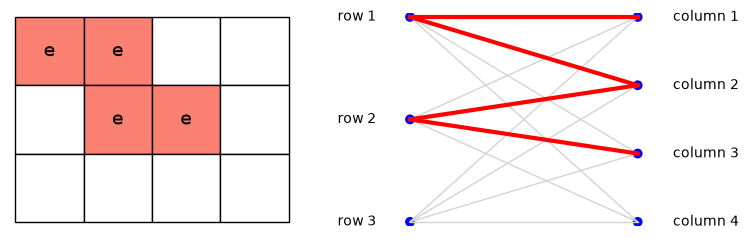

set()


In [10]:
path = {(1, 1), (1, 2), (2, 2), (2, 3)}
show_erasures(path)
print(peel(path, checks34))

矩形的四個角是長度 $4$ 的 cycle，  
每個 vertex 的 degree 都是 $0$ 或 $2$，一條邊也拔不掉。

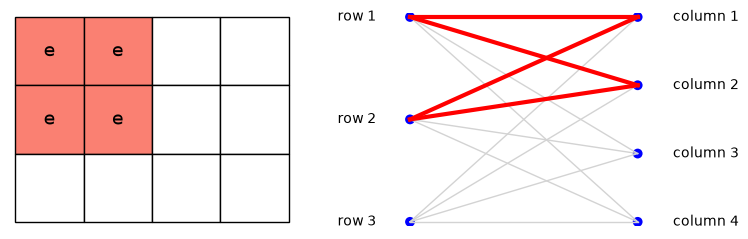

In [11]:
show_erasures({(1, 1), (1, 2), (2, 1), (2, 2)})

長度 $6$ 的 cycle 不含任何矩形，同樣卡住；  
前面 $3 \times 3$ 只留下對角線的例子，畫出來也是長度 $6$ 的 cycle。

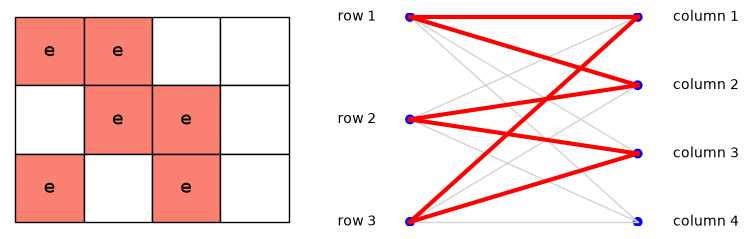

In [12]:
show_erasures({(1, 1), (1, 2), (2, 2), (2, 3), (3, 3), (3, 1)})

一般的 $S$ 是一些 cycles，再掛上一些樹枝。  
Peeling 把樹枝一根一根拔掉，最後剩下沒有 degree $1$ 的部分，  
也就是 $S$ 所包含的最大 stopping set。  
例如矩形再加上 $(2, 4)$：  
column $4$ 只有一個 $\mathrm e$，先被補回，剩下矩形。

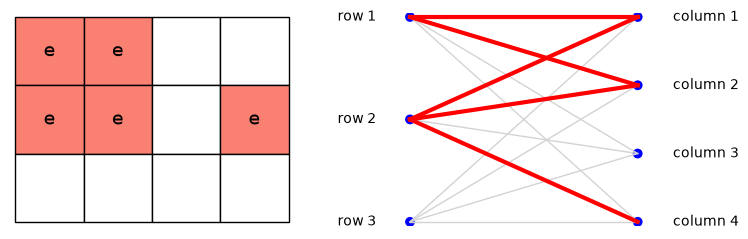

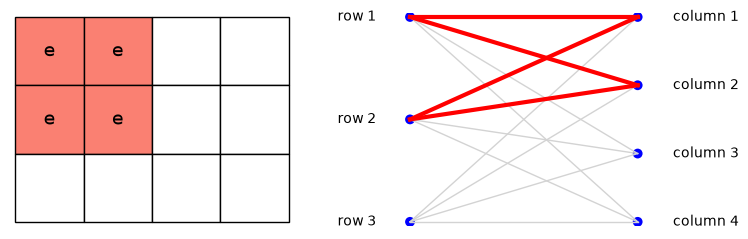

In [13]:
tail = {(1, 1), (1, 2), (2, 1), (2, 2), (2, 4)}
show_erasures(tail)
show_erasures(peel(tail, checks34))

因此非空的 stopping set 中，  
每個有邊的 vertex 的 degree 都至少是 $2$，  
所以圖中一定有 cycle。

Cycle 經過每個 vertex $0$ 次或 $2$ 次，  
所以 cycle 的邊在每個 row 與每個 column 都佔偶數個位置，  
是一個非零 codeword 的 support。  
因此 peeling 卡住時，$E$ 一定包含某個非零 codeword 的 support，  
此時任何 decoder 都不可能成功。  
對 SPC 的 product code，peeling 就是最好的 erasure decoder，  
這解釋了上表最後兩個 columns 為何相同。

一般的 code 不一定這麼幸運：  
可能有不含任何 codeword support 的 stopping sets，  
此時 Gaussian elimination 能補回，peeling 卻卡住。  
但 Gaussian elimination 對長度 $n$ 的 code 需要約 $n^3$ 次運算，  
peeling 每補回一個 bit 只需要看它所在的少數幾個 checks。

0929 週五作業的 randomized erasure decoder 也是 peeling，  
只是每次隨機抽一個 $\mathrm{RM}(2, 5)$ 的 check。

## Tanner Graphs

### Tanner graph

沿用課程的慣例：$\mathcal C = \{c : cH = 0\}$，$H$ 是 $n \times r$ 矩陣，  
$H$ 的第 $i$ 個 row 對應 bit $c_i$，  
第 $j$ 個 column 對應一個 parity check。

**Tanner graph**（Tanner 1981）是一個二部圖：  
一邊是 $n$ 個 **variable nodes**（VN），  
另一邊是 $r$ 個 **check nodes**（CN），  
$H_{ij} = 1$ 時在 VN $i$ 與 CN $j$ 之間連一條邊。  
$c \in \mathcal C$ 當且僅當每個 CN 的鄰居的 bits 加起來是 $0$。

VN $i$ 的 degree 是 $H$ 的第 $i$ 個 row 的 weight，  
也就是 bit $c_i$ 出現在幾個 checks 中；  
CN $j$ 的 degree 是第 $j$ 個 column 的 weight，  
也就是這個 check 包含幾個 bits。

在 Tanner graph 上，peeling 是說：  
恰好有一個鄰居是 $\mathrm e$ 的 CN 決定那個鄰居。  
Stopping set 則是一群 VNs，  
任何連到它們的 CN 都至少連到其中兩個。

$[9, 4, 4]$ 的 Tanner graph 有 $9$ 個 VNs 與 $6$ 個 CNs，  
後者是 $3$ 個 rows 與 $3$ 個 columns。  
每個 VN 的 degree 是 $2$，每個 CN 的 degree 是 $3$。  
$H$ 是 $9 \times 6$ 矩陣，rank 卻是 $5 = 9 - 4$：  
三個 row checks 的和與三個 column checks 的和  
都是全部 bits 的和，這正是 check on checks。

In [14]:
H = matrix(GF(2), 9, 6, lambda i, j: int(cells[i] in checks[j]))
print(H)
print(H.rank(), all(c * H == 0 for c in C))

[1 0 0 1 0 0]
[1 0 0 0 1 0]
[1 0 0 0 0 1]
[0 1 0 1 0 0]
[0 1 0 0 1 0]
[0 1 0 0 0 1]
[0 0 1 1 0 0]
[0 0 1 0 1 0]
[0 0 1 0 0 1]
5 True


矩形的四個角在 Tanner graph 上是一個長度 $8$ 的 cycle：  
bit $(1, 1)$、row $1$、bit $(1, 2)$、column $2$、  
bit $(2, 2)$、row $2$、bit $(2, 1)$、column $1$，再回到 bit $(1, 1)$。  
Tanner graph 中最短 cycle 的長度稱為 **girth**。

為什麼沒有更短的 cycle？  
Tanner graph 的 cycle 輪流經過 bits 與 checks。  
把每個 bit 看成前面 rows 與 columns 二部圖中的一條邊，  
長度 $2L$ 的 cycle 就是那張二部圖中長度 $L$ 的 cycle。  
$L = 2$ 需要兩個 bits 同在一個 row 又同在一個 column，不可能；  
二部圖也沒有長度 $3$ 的 cycle，所以 Tanner 的 girth 是 $8$。

換個角度看：$[9, 4, 4]$ 的 rows 與 columns 組成完全二部圖 $K_{3,3}$，  
每個 bit 是其中的一條邊。  
在每條邊的中點放一個 VN，把邊拆成兩段，  
rows 與 columns 就成了 CNs，得到的正是 Tanner graph。  
每個 cycle 的長度因此乘以二，girth 也乘以二：  
$K_{3,3}$ 的 girth 是 $4$（矩形），Tanner graph 的 girth 是 $8$。

## 高維 Product Codes

### 每個方向各解一次

令 $\mathcal C$ 是 $[n, k, d]$ code。  
$\ell$ 重 product code $\mathcal C^{\otimes\ell}$  
把 bits 放在 $\ell$ 維的格子 $\{1, \ldots, n\}^\ell$ 上，  
沿每個座標軸方向的每一條直線都是 $\mathcal C$ 的 codeword。  
由定理，它是 $[n^\ell, k^\ell, d^\ell]$ code，rate 是 $(k/n)^\ell$。

例如 $[n, n - 1, 2]^{\otimes\ell}$ 的 checks 是平行於座標軸的直線，  
每條直線上的 $n$ 個 bits 加起來是 $0$。  
每個 bit 恰好在 $\ell$ 條直線上，每條直線恰好有 $n$ 個 bits，  
所以 VNs 的 degree 都是 $\ell$，CNs 的 degree 都是 $n$。

Elias（1954）的解碼順序是：  
先沿第 $1$ 個方向，把每條直線各自解碼；  
先沿第 $2$ 個方向，把每條直線各自解碼；  
再沿第 $3$ 個方向，依此類推，每個方向只解一次。

令 $x_j$ 是解完前 $j$ 個方向後，一個 bit 仍然錯誤或仍是 $\mathrm e$ 的機率。  
這樣的 $x_j$ 會滿足一個完美的遞迴，  
這是最簡單、而且完全精確的 density evolution。

### 獨立性來自乘積

沿第 $j + 1$ 個方向的一條直線上，  
$n$ 個 bits 只有第 $j + 1$ 個座標不同。  
解前 $j$ 個方向時，一個 bit 的結果只取決於它所在的切片：  
第 $j + 1$ 個以後的座標都和它相同的那些 bits。  
同一條直線上的 $n$ 個 bits 屬於 $n$ 個互不相交的切片。  
Channel 是 memoryless，  
所以這 $n$ 個 bits 在第 $j$ 步之後的對錯彼此獨立，機率都是 $x_j$。

### BEC 與 SPC

在 $\operatorname{BEC}(\epsilon)$ 上用 $[n, n - 1, 2]$ code：  
直線上恰好有一個 $\mathrm e$ 時補回它。  
一個 bit 在下一步之後仍是 $\mathrm e$，當且僅當它本來是 $\mathrm e$，  
而且同一條直線的其他 $n - 1$ 個 bits 中至少有一個 $\mathrm e$：
$$x_{j+1} = x_j\bigl(1 - (1 - x_j)^{n-1}\bigr),\qquad x_0 = \epsilon.$$

下面取 $n = 8$、$\ell = 4$、$\epsilon = 0.2$，比較遞迴與模擬。  
SageMath 把程式中的整數常數換成自己的 `Integer`，  
numpy 的 random generator 需要 Python 的 `int`，  
所以 seed 寫成 `int(1109)`。

In [15]:
import numpy as np

rng = np.random.default_rng(int(1109))

In [16]:
def spc_de(n, eps, steps):
    xs = [eps]
    for _ in range(steps):
        xs.append(xs[-1] * (1 - (1 - xs[-1])**(n - 1)))
    return xs

模擬時，`E` 是 $\ell$ 維的 boolean array，標出哪些 bits 是 $\mathrm e$。  
`spc_sweep` 沿第 $k$ 個方向解碼：  
直線上至少有兩個 $\mathrm e$ 時，這些 $\mathrm e$ 留下來。  
`grid_sim` 依序沿各個方向解碼，記下每一步之後 $\mathrm e$ 的比例。

In [17]:
def spc_sweep(E, k):
    return E & (E.sum(axis=k, keepdims=True) >= 2)

In [18]:
def grid_sim(sweep, n, x0, ell, rounds=1, trials=200):
    xs = np.zeros(ell * rounds + 1)
    for _ in range(trials):
        E = rng.random((n,) * ell) < x0
        xs[0] += E.mean()
        for t in range(ell * rounds):
            E = sweep(E, t % ell)
            xs[t + 1] += E.mean()
    return xs / trials

In [19]:
print([round(x, 4) for x in spc_de(8, 0.2, 4)])
print(np.round(grid_sim(spc_sweep, 8, 0.2, 4), 4))

[0.2, 0.1581, 0.1107, 0.062, 0.0224]
[0.2001 0.1581 0.1107 0.0618 0.0224]


令 $X_j$ 是解完前 $j$ 個方向後 $\mathrm e$ 的個數。  
每個 bit 仍是 $\mathrm e$ 的機率都是 $x_j$，所以 $\mathbb E[X_j] = n^\ell x_j$。  
下圖的藍線是十次模擬的 $X_j$，紅線是 $\mathbb E[X_j]$。  
這張圖另外用一個 random generator，  
後面的模擬結果才不會跟著改變。

In [20]:
def grid_run(sweep, n, x0, ell, gen, rounds=1):
    E = gen.random((n,) * ell) < x0
    counts = [E.sum()]
    for t in range(ell * rounds):
        E = sweep(E, t % ell)
        counts.append(E.sum())
    return counts

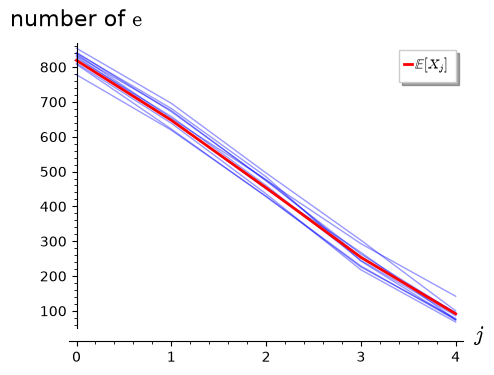

In [21]:
gen = np.random.default_rng(int(10))
fig = sum((line(list(enumerate(grid_run(spc_sweep, 8, 0.2, 4, gen))), color="blue", alpha=0.4) for _ in range(10)), Graphics())
fig += line([(j, 8**4 * x) for j, x in enumerate(spc_de(8, 0.2, 4))], color="red", thickness=2,
            legend_label=r"$\mathbb{E}[X_j]$")
fig.show(axes_labels=[r"$j$", r"number of $\mathrm{e}$"], ticks=[1, 100], figsize=5)

兩者一致，因為前面的獨立性是精確的，不是近似。  
對任何 $\epsilon < 1$ 都有 $x_{j+1} < x_j$，所以方向越多，$\mathrm e$ 越少；  
$x_j$ 很小時 $x_{j+1} \approx (n - 1)x_j^2$，下降得非常快。  
但 rate $(1 - 1/n)^\ell$ 也隨 $\ell$ 趨近 $0$：  
$n = 8$、$\ell = 4$ 的 rate 只剩 $0.586$，而 $x_4$ 還有 $0.022$。

### 再掃一輪

解完 $\ell$ 個方向後，可以再從第 $1$ 個方向開始掃。  
但這時獨立性不再成立：  
例如 $\ell = 2$ 時，矩形的四個角是 Tanner graph 中長度 $8$ 的 cycle，  
同一條直線上的 bits 不再來自互不相交的切片。  
下面取 $n = 8$、$\ell = 2$、$\epsilon = 0.3$ 掃三輪，和照抄遞迴的結果比較。

In [22]:
avg = grid_sim(spc_sweep, 8, 0.3, 2, rounds=3, trials=5000)
print([round(x, 4) for x in spc_de(8, 0.3, 6)])
print(np.round(avg, 4))

[0.3, 0.2753, 0.2464, 0.2124, 0.1724, 0.1266, 0.0775]
[0.2986 0.2737 0.2445 0.2364 0.2337 0.2327 0.2325]


下圖的藍線是十次模擬的 $X_j$，紅線是照抄遞迴的 $n^\ell x_j$，  
黑色虛線是 $5{,}000$ 次模擬的平均，也就是真正的 $\mathbb E[X_j]$。

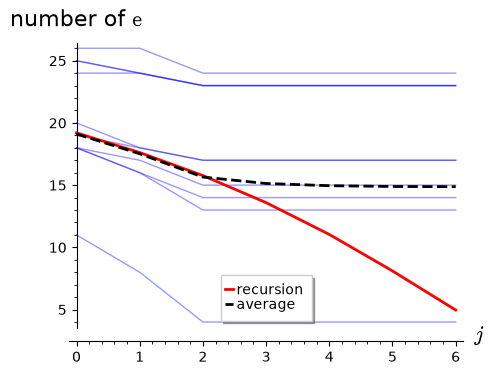

In [23]:
gen = np.random.default_rng(int(11))
fig = sum((line(list(enumerate(grid_run(spc_sweep, 8, 0.3, 2, gen, rounds=3))), color="blue", alpha=0.4) for _ in range(10)), Graphics())
fig += line([(j, 64 * x) for j, x in enumerate(spc_de(8, 0.3, 6))], color="red", thickness=2, legend_label="recursion")
fig += line([(j, 64 * x) for j, x in enumerate(avg)], color="black", thickness=2, linestyle="--", legend_label="average")
fig.show(axes_labels=[r"$j$", r"number of $\mathrm{e}$"], ticks=[1, 5], figsize=5)

前兩步一致，之後遞迴繼續下降，模擬卻停在 $0.235$ 左右。  
停下來的 $\mathrm e$ 是 stopping sets：  
每個 row 與每個 column 都含有 $0$ 個或至少兩個 $\mathrm e$，  
例如矩形的四個角。  
遞迴假設獨立，所以看不到這些 cycles。

### BSC 與 Hamming codes

在 $\operatorname{BSC}(p)$ 上，SPC 只能發現奇數個 errors，不能更正。  
要讓每條直線更正一個 error，需要 $d = 3$：  
用 0914 講義的 Hamming code $[n, n - m, 3]$，其中 $n = 2^m - 1$。  
Hamming code 是 perfect code，  
每個收到的向量都恰好在一個 codeword 的距離 $1$ 以內，  
decoder 輸出那個 codeword。

固定傳送 all-zero codeword。  
解碼後 bit $i$ 錯誤，當且僅當 decoder 輸出的 codeword $c$ 有 $c_i = 1$。  
收到的向量落在某個 weight 為 $w$ 的 codeword 的距離 $1$ 以內，機率是
$$\begin{aligned}
P_w(p) &= p^w (1 - p)^{n-w} + wp^{w-1} (1 - p)^{n-w+1} \\
&\quad + (n - w)p^{w+1} (1 - p)^{n-w-1}.
\end{aligned}$$

1102 講義證明了 Hamming code 在適當的座標順序下是 cyclic，  
所以每個位置落在同樣多個 weight 為 $w$ 的 codewords 中，  
也就是 $wA_w/n$ 個；  
$A_w$ 是 0921 講義算出的 weight 分布。

因此
$$x_{j+1} = f(x_j),\qquad f(p) = \sum_{w\ge1}\frac{wA_w}{n} P_w(p).$$

$p$ 很小時，主項來自 $2$ 個 errors：decoder 會把第三個 bit 也翻錯，  
所以 $f(p) \approx \frac32(n - 1)p^2$。  
下面用 0921 講義的 $W_{\mathrm{Ham}_m}(z)$ 得到 $A_w$。

In [24]:
z = polygen(QQ, "z")

@cached_function
def hamming_weights(m):
    n = 2**m - 1
    return (((1 + z)**n + n * (1 + z)**(2**(m - 1) - 1) * (1 - z)**(2**(m - 1))) / 2**m).list()

def hamming_f(m, p):
    n, A = 2**m - 1, hamming_weights(m)
    P = lambda w: (p**w * (1 - p)**(n - w) + w * p**(w - 1) * (1 - p)**(n - w + 1)
                   + (n - w) * p**(w + 1) * (1 - p)**(n - w - 1))
    return sum(w * A[w] / n * P(w) for w in range(1, n + 1) if A[w])

模擬時把 $H$ 的第 $i$ 個 row 取為 $i$ 的二進位，$i = 1, \ldots, n$。  
Syndrome 就是錯誤位置的二進位 XOR，  
不為零時翻轉它指到的位置。  
SageMath 中 `^` 是次方，所以 `hamming_sweep` 用 `!=` 做 XOR。

In [25]:
def hamming_sweep(E, k):
    idx = np.arange(1, E.shape[k] + 1).reshape([-1 if a == k else 1 for a in range(E.ndim)])
    s = np.bitwise_xor.reduce(np.where(E, idx, 0), axis=k, keepdims=True)
    return E != (idx == s)

In [26]:
xs = [0.05]
for _ in range(4):
    xs.append(hamming_f(3, xs[-1]))
print([round(x, 5) for x in xs])
print(np.round(grid_sim(hamming_sweep, 7, 0.05, 4), 5))

[0.05, 0.01943, 0.00321, 9e-05, 0.0]
[4.976e-02 1.924e-02 3.050e-03 5.000e-05 0.000e+00]


同樣畫出十次模擬的 errors 個數 $X_j$（藍線）  
與 $\mathbb E[X_j] = n^\ell x_j$（紅線），  
這裡 $n = 7$、$\ell = 4$、$p = 0.05$。

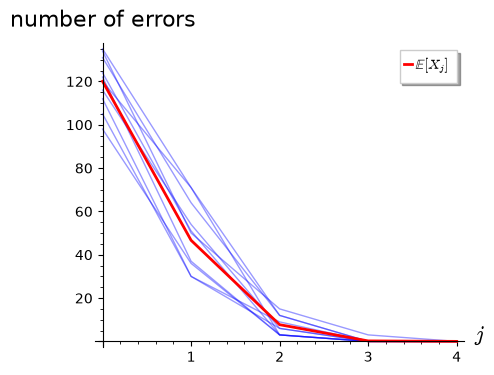

In [27]:
gen = np.random.default_rng(int(12))
fig = sum((line(list(enumerate(grid_run(hamming_sweep, 7, 0.05, 4, gen))), color="blue", alpha=0.4) for _ in range(10)), Graphics())
fig += line([(j, 7**4 * x) for j, x in enumerate(xs)], color="red", thickness=2, legend_label=r"$\mathbb{E}[X_j]$")
fig.show(axes_labels=[r"$j$", "number of errors"], ticks=[1, 20], figsize=5)

### 錯誤太多時，越更正錯越多

BEC 上的 SPC 從不製造新的 $\mathrm e$，所以 $x_j$ 一定下降。  
BSC 上的 Hamming decoder 遇到 $2$ 個 errors 會再翻錯一個 bit，  
所以可能 $f(p) > p$。  
$f(p) = p$ 最小的正根就是 threshold：  
$x_0$ 小於它時 $x_j \to 0$，大於它時方向再多，errors 也不會消失。

In [28]:
p = var("p")
for m in [3, 4, 5]:
    print(2**m - 1, find_root(hamming_f(m, p) - p, 0.01, 2 / 2**m))

7 0.21132486540518697
15 0.09015047337164737
31 0.04197142653862993


最經典的畫法是把 $f$ 與對角線畫在一起：  
遞迴 $x_{j+1} = f(x_j)$ 就是在兩條線之間走階梯，  
兩條線的交點就是 threshold。  
$x_0 = 0.18$ 在交點左邊，階梯往 $0$ 走；  
$x_0 = 0.24$ 在交點右邊，階梯往上走。

In [29]:
def cobweb(x0, steps):
    pts = [(x0, 0)]
    for _ in range(steps):
        y = hamming_f(3, x0)
        pts += [(x0, y), (y, y)]
        x0 = y
    return line(pts, color="blue")

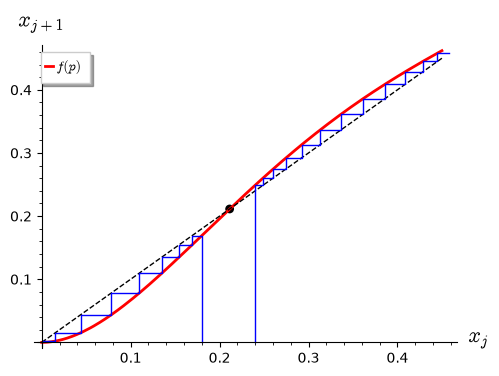

In [30]:
fig = plot(hamming_f(3, p), (p, 0, 0.45), color="red", thickness=2, legend_label=r"$f(p)$")
fig += plot(p, (p, 0, 0.45), color="black", linestyle="--")
fig += cobweb(0.18, 12) + cobweb(0.24, 12) + point((0.2113, 0.2113), size=40, color="black")
fig.show(axes_labels=[r"$x_j$", r"$x_{j+1}$"], figsize=5)

In [31]:
def cobweb_frame(steps):
    fig = plot(hamming_f(3, p), (p, 0, 0.45), color="red", thickness=2) + plot(p, (p, 0, 0.45), color="black", linestyle="--")
    fig += cobweb(0.18, steps) + cobweb(0.24, steps) + point((0.2113, 0.2113), size=40, color="black")
    name = tmp_filename(ext=".png")
    fig.save(name, xmin=0, xmax=0.45, ymin=0, ymax=0.47, axes_labels=[r"$x_j$", r"$x_{j+1}$"], figsize=5)
    return Image.open(name).convert("RGB")

In [32]:
from pathlib import Path
from PIL import Image

gif = Path("1109/staircases-move-away-from-threshold.gif")
gif.parent.mkdir(exist_ok=True)
frames = [cobweb_frame(steps) for steps in range(1, 13)]
frames[0].save(gif, save_all=True, append_images=frames[1:], duration=[700] * 11 + [2500], loop=0)
print(f"Saved {len(frames)} frames to {gif}")

Saved 12 frames to 1109/staircases-move-away-from-threshold.gif


動畫一步一步畫出同樣的兩條階梯：  
![從 0.18 與 0.24 出發的兩條階梯，分別離開交點往下與往上走](1109/staircases-move-away-from-threshold.gif)

下圖取 $n = 7$、$\ell = 6$，  
比較 threshold 兩側的 $p = 0.18$ 與 $p = 0.24$。  
藍線是各五次模擬的 errors 比例，紅線是遞迴給的 $x_j$。  
$p = 0.18$ 的 errors 越降越快；$p = 0.24$ 的 errors 反而越來越多。

In [33]:
def hamming_de(p0, steps):
    xs = [p0]
    for _ in range(steps):
        xs.append(hamming_f(3, xs[-1]))
    return xs

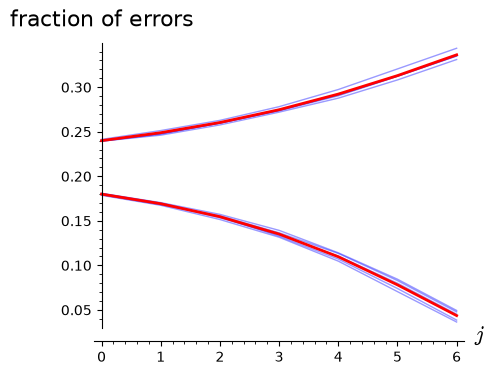

In [34]:
gen = np.random.default_rng(int(13))
fig = Graphics()
for p0 in [0.18, 0.24]:
    fig += sum((line([(j, c / 7**6) for j, c in enumerate(grid_run(hamming_sweep, 7, p0, 6, gen))],
                     color="blue", alpha=0.4) for _ in range(5)), Graphics())
    fig += line(list(enumerate(hamming_de(p0, 6))), color="red", thickness=2)
fig.show(axes_labels=[r"$j$", "fraction of errors"], ticks=[1, 0.05], figsize=5)

直線越長，越容易出現 $2$ 個 errors，所以 threshold 隨 $n$ 變小。  
Elias 讓每個方向的 code 越來越長，rate 才不會趨近 $0$，  
能承受多大的 $p$ 則主要由第一個方向的 $n$ 決定，見延伸話題。

### 每個方向越來越長

每個方向都用同一個 code 時，  
要讓錯誤趨近 $0$，就得讓方向數 $\ell \to \infty$，  
rate $(k/n)^\ell$ 也跟著趨近 $0$。  
Elias（1954）讓各方向的 code 越來越長，例如長度每次加倍。  
前面獨立性的論證沒有用到各方向等長，所以遞迴照樣成立，  
只是第 $j + 1$ 步用第 $j + 1$ 個方向的長度 $n_{j+1}$。

Rate 是 $\prod_j k_j/n_j$。  
只要各方向的 redundancy 比例 $1 - k_j/n_j$ 加起來有限，  
這個無窮乘積就收斂到正數。  
長度加倍時，SPC 的 $1/n_j$ 加起來有限，  
Hamming code 的 $m_j/(2^{m_j} - 1)$ 也是。

In [35]:
def elias(step, lengths, x0):
    xs = [x0]
    for n in lengths:
        xs.append(step(n, xs[-1]))
    return xs

### BEC：SPC 的長度加倍

取 $n_j = 2^{j+2}$，也就是 $8, 16, 32, \ldots$，  
rate 是 $\prod_{j\ge1}(1 - 2^{-j-2}) \approx 0.77$。  
由 Bernoulli 不等式 $1 - (1 - x)^{n-1} \le (n - 1)x$，
$$x_{j+1} \le n_{j+1} x_j^2.$$
令 $y_j = n_{j+1} x_j$，因為 $n_{j+2} = 2n_{j+1}$，  
得到 $2y_{j+1} \le (2y_j)^2$。

所以 $2y_0 = 2n_1\epsilon < 1$ 時，$2y_j$ 每一步至少平方一次，  
$x_j$ 以 doubly exponential 的速度趨近 $0$。  
這只是充分條件：取 $n_1 = 8$ 時，條件要求 $\epsilon < 1/16$，  
實際上 $\epsilon$ 小於約 $0.091$ 都收斂。  
下圖每個 $j$ 一條線：$\epsilon$ 小時，$j$ 每加一，$x_j$ 就掉好幾個數量級；  
$\epsilon$ 超過約 $0.091$ 時，各條線擠在一起，  
$x_j$ 停在某個正數：直線越來越長，SPC 補不動。

In [36]:
def spc_elias(eps, n1, steps=20):
    return elias(lambda n, x: x * (1 - (1 - x)**(n - 1)), [n1 * 2**j for j in range(steps)], eps)

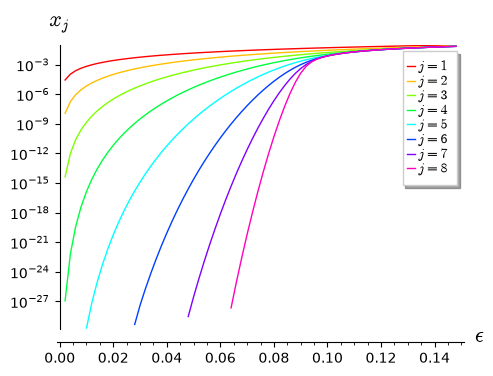

In [37]:
eps_grid = srange(0.002, 0.15, 0.002)
runs = [spc_elias(eps, 8, 8) for eps in eps_grid]
fig = Graphics()
for j, color in zip(range(1, 9), rainbow(8)):
    fig += line([(eps, xs[j]) for eps, xs in zip(eps_grid, runs) if xs[j] > 1e-30], color=color, legend_label=r"$j = %d$" % j)
fig.show(scale="semilogy", axes_labels=[r"$\epsilon$", r"$x_j$"], figsize=5)

### BSC：Hamming codes 的長度加倍

取 $n_j = 2^{j+2} - 1$，也就是 $7, 15, 31, \ldots$，rate 約為 $0.28$。  
前面看到 $f(p) \approx \frac32(n - 1)p^2$，  
令 $y_j = \frac32 n_{j+1} x_j$，同樣得到 $2y_{j+1} \approx (2y_j)^2$，  
所以近似的條件是 $3n_1 p < 1$。

$m > 10$ 時，也就是 $n > 1{,}023$，直接用主項 $\frac32(n - 1)p^2$ 計算，  
收斂時那裡的 $x_j$ 已經很小，主項很準確。  
下圖取 $n_1 = 7$，每個 $j$ 一條線：  
$p$ 小於約 $0.061$ 時收斂，超過之後 $x_j$ 不再下降。

In [38]:
def ham_step(m, p):
    return hamming_f(m, p) if m <= 10 else 1.5 * (2**m - 2) * p**2

def ham_elias(p0, m1, steps=16):
    return elias(ham_step, range(m1, m1 + steps), p0)

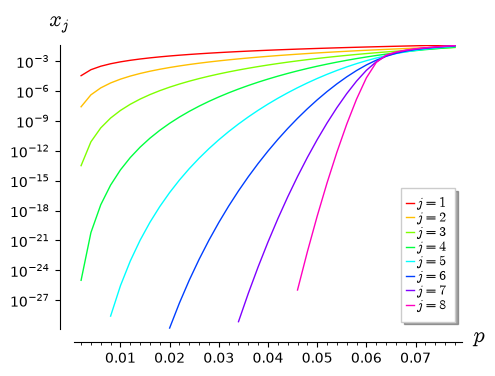

In [39]:
p_grid = srange(0.002, 0.08, 0.002)
runs = [ham_elias(p0, 3, 8) for p0 in p_grid]
fig = Graphics()
for j, color in zip(range(1, 9), rainbow(8)):
    fig += line([(p0, xs[j]) for p0, xs in zip(p_grid, runs) if xs[j] > 1e-30], color=color, legend_label=r"$j = %d$" % j)
fig.show(scale="semilogy", axes_labels=[r"$p$", r"$x_j$"], figsize=5)

### 離 capacity 還很遠

Shannon 的 channel coding theorem 說：  
$\operatorname{BEC}(\epsilon)$ 的 capacity 是 $1 - \epsilon$，  
$\operatorname{BSC}(p)$ 的 capacity 是 $1 - h(p)$，  
其中 $h(p) = -p\log_2 p - (1 - p)\log_2(1 - p)$；  
rate 小於 capacity 時，存在錯誤趨近 $0$ 的 codes。  
下週再仔細說明。

下圖對每個 $\epsilon$ 或 $p$，在所有第一層的長度中，  
挑出讓錯誤趨近 $0$、而且 rate 最大的那一個，  
和 capacity（虛線）比較。  
第一層的長度只取 $2$ 的冪次，所以曲線是階梯。

In [40]:
def spc_rate(n1):
    return prod(1 - 1 / (n1 * 2**j) for j in range(60))

def ham_rate(m1):
    return prod(1 - m / (2**m - 1) for m in range(m1, m1 + 60))

def best_rate(run, rate, starts, x0):
    return max([rate(s) for s in starts if run(x0, s)[-1] < 1e-12], default=0)

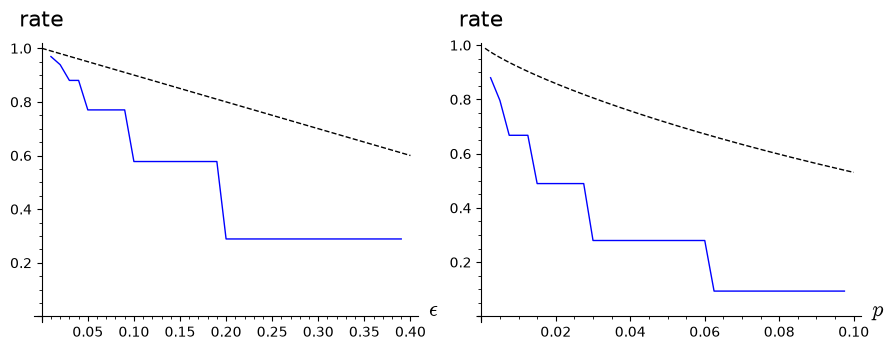

In [41]:
bec = line([(e, best_rate(spc_elias, spc_rate, [2**k for k in range(1, 12)], e)) for e in srange(0.01, 0.4, 0.01)])
bec += plot(1 - p, (p, 0, 0.4), color="black", linestyle="--")
bsc = line([(q, best_rate(ham_elias, ham_rate, range(2, 11), q)) for q in srange(0.0025, 0.1, 0.0025)])
bsc += plot(1 + p * log(p, 2) + (1 - p) * log(1 - p, 2), (p, 0.001, 0.1), color="black", linestyle="--")
bec.axes_labels([r"$\epsilon$", "rate"])
bsc.axes_labels([r"$p$", "rate"])
bec.set_axes_range(ymin=0)
bsc.set_axes_range(ymin=0)
graphics_array([bec, bsc]).show(figsize=[9, 3.5])

這就是 Elias 的結論：rate 是正的，錯誤趨近 $0$。  
這是第一個做到這件事的 explicit 構造，但 rate 離 capacity 還很遠：  
每個方向的 code 都太弱，為了讓錯誤開始下降，第一層必須很短，  
rate 就被第一層卡住。

### 從乘積結構到隨機的 graph

乘積結構的代價有兩個：  
每個方向只能解一次，再掃就失去獨立性；  
每個方向的 code 都很弱，rate 離 capacity 很遠。  
隨機的 LDPC codes 放棄乘積結構，  
改用「周圍很大的範圍是一棵樹」來取得獨立性，  
而且可以反覆解碼。  
這是下週的主題。

## 週五作業

### BEC 與 Hamming codes

講義在 BEC 上用 SPC（$d = 2$），  
在 BSC 上用 Hamming code（$d = 3$）。  
這份作業在 BEC 上改用 Hamming code $[n, n - m, 3]$。

1. 證明一條直線上至多 $2$ 個 $\mathrm e$ 時，就可以補回來。

2. 每個 bit 獨立地以機率 $x$ 是 $\mathrm e$，  
   令 $g(x)$ 是解完直線後仍是 $\mathrm e$ 的機率。  
   證明因為直線上至少有 $3$ 個 $\mathrm e$，  
   所以 $g(x) \le \binom{n-1}{2}x^3$。

3. 仿照講義的長度加倍：SPC 取 $n_j = 2^{j+2}$，  
   Hamming code 取 $n_j = 2^{j+2} - 1$。  
   SPC 有 $d = 2$，同樣的論證給出 $x_{j+1} \le (n_{j+1} - 1)x_j^2$，  
   另外 $x_{j+1} \le x_j$ 一定成立。  
   用這些上界對 $j = 1, \ldots, 8$ 畫出 $x_j$ 的上界對 $\epsilon$ 的圖，  
   兩種 codes 各一張，SPC 那張和講義的精確值比較。  
   兩者的 rate 分別是多少？哪一個划算？

圖的形式和講義的這張圖一樣：  
![長度加倍時 SPC 的 x_j 對 ε 的圖，每個 j 一條線](1109/spc-doubling-erasure-vs-epsilon.png)

4. 長度和第 3 題相同，令 $y_j = n_{j+1} x_j$。  
   用第 2 題證明 Hamming code 有 $y_{j+1} \le y_j^3$，  
   所以 $n_1\epsilon < 1$ 時 $x_j \to 0$。  
   提示：$n_{j+2} = 2n_{j+1} + 1$，而且 $(2n + 1)\binom{n-1}{2} \le n^3$。  
   對每個 $\epsilon$，在 $n_1 = 3, 7, 15, \ldots$ 中  
   挑出滿足 $n_1\epsilon < 1$、rate 最大的，畫出 rate 對 $\epsilon$ 的階梯圖，  
   和 capacity $1 - \epsilon$ 與講義的 SPC 比較。

階梯圖應該長得像下圖的紅線，但請自己用程式畫一張；  
藍線是講義的 SPC，虛線是 capacity。  
![長度加倍時 SPC（藍）與 Hamming code（紅）在 BEC 上的最佳 rate 對 ε 的階梯圖，虛線是 capacity](1109/elias-rate-vs-capacity-bec.png)

額外練習不用交：
- $n = 7$ 時，用 SageMath 列舉 $2^7$ 種 erasure patterns，  
  算出 $g(x)$ 的精確多項式，和第 2 題的上界比較。
- $35$ 種 $3$ 個 $\mathrm e$ 的 patterns 中，有幾種補不回來？  
  它們有什麼共同點？
- 對 $2^7$ 種 patterns 建表，寫出 `hamming_erasure_sweep(E, k)`，  
  用講義的 `grid_run` 驗證精確的遞迴。

### 週一作業

#### Extended Hamming codes 的 density evolution

講義在 BSC 上用 Hamming code $[n, n - m, 3]$。  
Elias（1954）實際用的是 extended Hamming code，  
也就是 Hamming code 再加一個 overall parity bit：  
$[N, N - m - 1, 4]$，其中 $N = 2^m$。  
這份作業比較兩者，  
只用 distance 的保證與主項，不需要算 weight 分布。

把 $H$ 的第 $i$ 個 row 取為 $1$ 接上 $i$ 的二進位，$i = 0, \ldots, N - 1$。  
沿一條直線解碼時，syndrome 的第一個 bit 是 overall parity，  
其餘的 bits 記為 $s$：
- overall parity 是 $1$ 時，翻轉位置 $s$；
- overall parity 是 $0$ 而且 $s \ne 0$ 時，偵測到錯誤但不更正，  
  這條直線保持原樣。

1. 證明 decoder 一定更正 $0$ 或 $1$ 個 errors；  
   $2$ 個 errors 時一定偵測得到，這條直線保持原樣。  
   講義的 Hamming code 遇到 $2$ 個 errors 時，解碼後會有幾個 errors？

2. 用第 1 題說明：  
   $p$ 很小時，一個 bit 解碼後仍錯誤的機率約為 $(N - 1)p^2$，  
   而講義的 Hamming code 是 $\frac32(n - 1)p^2$。  
   係數 $\frac32$ 從哪裡來？

3. 仿照講義的長度加倍：Hamming code 取 $n_j = 2^{j+2} - 1$，  
   extended Hamming code 取 $N_j = 2^{j+2}$。  
   用第 2 題的主項遞迴，對 $j = 1, \ldots, 8$ 畫出 $x_j$ 對 $p$ 的圖，  
   兩種 codes 各一張，Hamming code 那張和講義的精確值比較。  
   兩者的 rate 分別是多少？

圖的形式和講義的這張圖一樣：
![長度加倍時 Hamming code 的 x_j 對 p 的圖，每個 j 一條線](1109/hamming-doubling-error-vs-p.png)

4. 令 $y_j = N_{j+1} x_j$，由主項推出 $2y_{j+1} \approx (2y_j)^2$，  
   所以近似的條件是 $2N_1 p < 1$；  
   講義的 Hamming code 是 $3n_1 p < 1$。  
   對每個 $p$，在 $N_1 = 4, 8, 16, \ldots$ 中  
   挑出滿足 $2N_1 p < 1$、rate 最大的，畫出 rate 對 $p$ 的階梯圖，  
   和 capacity $1 - h(p)$ 與講義的 Hamming code 比較。

階梯圖應該長得像下圖的紅線，但請自己用程式畫一張；  
藍線是講義的 Hamming code，虛線是 capacity。
![長度加倍時 Hamming code（藍）與 extended Hamming code（紅）在 BSC 上的最佳 rate 對 p 的階梯圖，虛線是 capacity](1109/elias-rate-vs-capacity-bsc.png)

額外練習不用交：  
令 $\tilde A_w$ 是 extended Hamming code 的 weight 分布，  
0921 講義已經算出來。  
由 0921 週一作業，  
extended Hamming code 在 $\operatorname{AGL}(m, 2)$ 之下不變。  
證明解碼後一個 bit 錯誤的機率精確地是  
$\tilde f(p) = \tilde f_1(p) + \tilde f_2(p)$，其中

$$\begin{aligned}
\tilde f_1(p) &= \sum_w\frac{w\tilde A_w}{N}\Bigl(wp^{w-1} (1 - p)^{N-w+1} \\
&\qquad + (N - w)p^{w+1} (1 - p)^{N-w-1}\Bigr), \\
\tilde f_2(p) &= \frac p2\bigl(1 - (1 - 2p)^{N-1}\bigr).
\end{aligned}$$

$\tilde f_1$ 來自奇數個 errors，$\tilde f_2$ 來自偶數個 errors。  
接著：
- 用 SageMath 因式分解 $\tilde f(p) - p$，  
  證明每個方向都用 $N = 8$ 時 threshold 是 $1 - 1/\sqrt2 \approx 0.293$；  
  講義 $n = 7$ 的 threshold 則是 $(3 - \sqrt3)/6 \approx 0.211$。
- 算出 $N = 16$ 與 $N = 32$ 的 threshold，  
  和講義的 $n = 15$、$31$ 比較。

- 偵測到錯誤時，改成把整條直線標成 $\mathrm e$，  
  下一個方向用 errors-and-erasures decoding。  
  寫出 errors 比例與 $\mathrm e$ 比例的遞迴主項，  
  比較 $p$ 很小時與接近 threshold 時，這個做法是贏還是輸。

- 把講義的 `hamming_sweep` 改成 extended Hamming code 的版本，  
  用 `grid_run` 模擬 $N = 8$、$\ell = 3$、$p = 0.02$，  
  和第 2 題主項的遞迴比較。